### 1. Import libraries

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline

# Data preprocessing
from sklearn.model_selection import train_test_split
from sklearn import preprocessing
from sklearn.preprocessing import StandardScaler

# Model selection
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

# Model performance evaluation
from sklearn import metrics
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

# Hyperparameter selection/Model optimisation
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.model_selection import GridSearchCV

#### I am using the dataset from the Diagnostic Wisconsin Breast Cancer Database. The dataset contains 30 features derived from images of breast tissue cell nuclei. There are 569 instances and the target variable is determining whether the cell tissue is malignant or benign.  


### 2. Read the data

In [2]:
file_path = '/content/drive/MyDrive/wdbc.data'
df = pd.read_csv(file_path)
df.head()

,842302,M,17.99,10.38,122.8,1001,0.1184,0.2776,0.3001,0.1471,...,25.38,17.33,184.6,2019,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189
0,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
1,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
2,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
3,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678
4,843786,M,12.45,15.70,82.57,477.1,0.12780,0.17000,0.1578,0.08089,...,15.47,23.75,103.40,741.6,0.1791,0.5249,0.5355,0.1741,0.3985,0.12440


In [7]:
# We need to label the columns using the 10 feature names from the wdbc.names doc

feature_names = ["radius", "texture", "perimeter", "area", "smoothness", "compactness",
        "concavity", "concave_points", "symmetry", "fractal_dimension"]
columns = [f"{b}_{stat}" for stat in ["mean", "se", "worst"] for b in feature_names]

df = pd.read_csv(file_path, header=None, names=["id", "diagnosis"] + columns)
df = df.drop(columns=["id"]) # Removing the patient id as the model doesn't need that data
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    object 
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave_points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                  5

The info above tells me that the dataset does have 569 entries and 30 numerical columns. The diagnosis column is the target column and contains the binary classification. There are no missing values.

### 3. Exploratory Data Analysis

#### Histograms

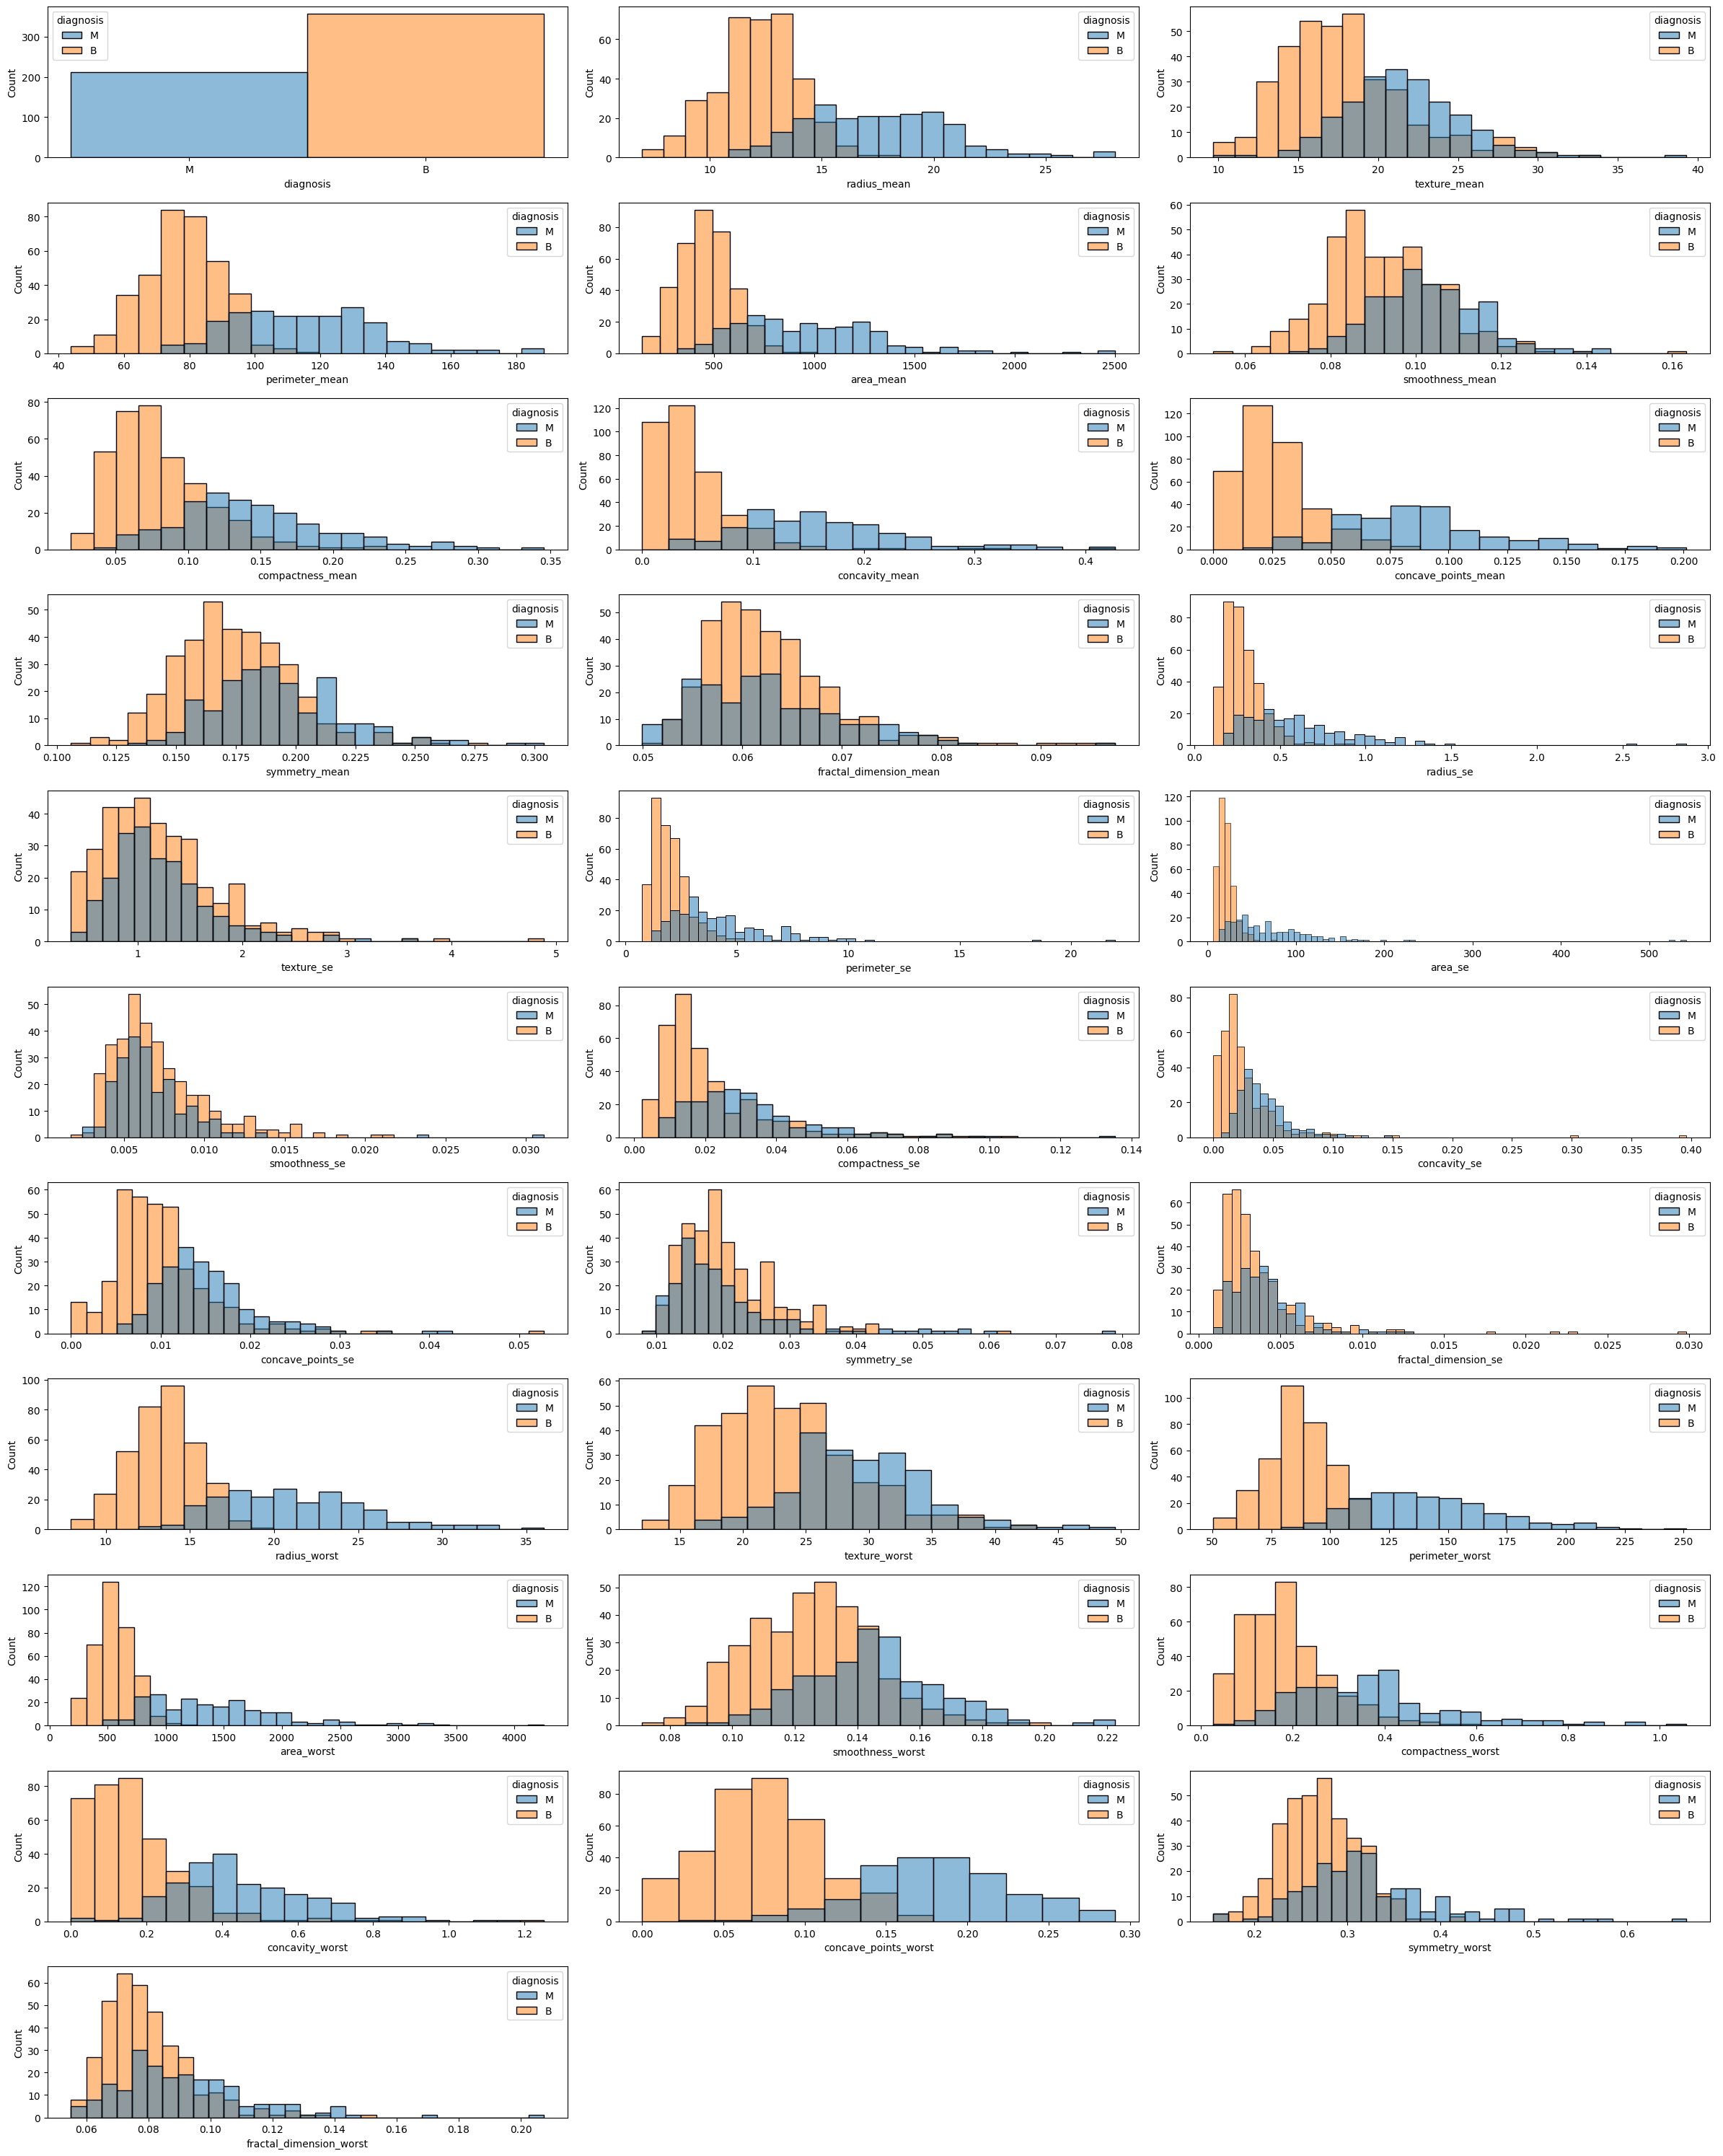

In [13]:
fig= plt.figure(figsize=(24, 30))
count=0
for column in df.columns:
  subfigure=fig.add_subplot(11,3,count+1)
  subfigure.set_xlabel(column)
  sns.histplot(data=df, x=df[column], hue='diagnosis')
  count+=1
plt.tight_layout()

I chose a histogram because these features are all numerical values. The bins are colour-coded according to the target variable, ie malignant or benign, this shows the distribution of each diagnosis in each feature. We see that thse size features (radius, perimeter and area) and concave have the greatest separation. This indicates that these feature have the most correlaton with the diagnosis.

#### Box Plots

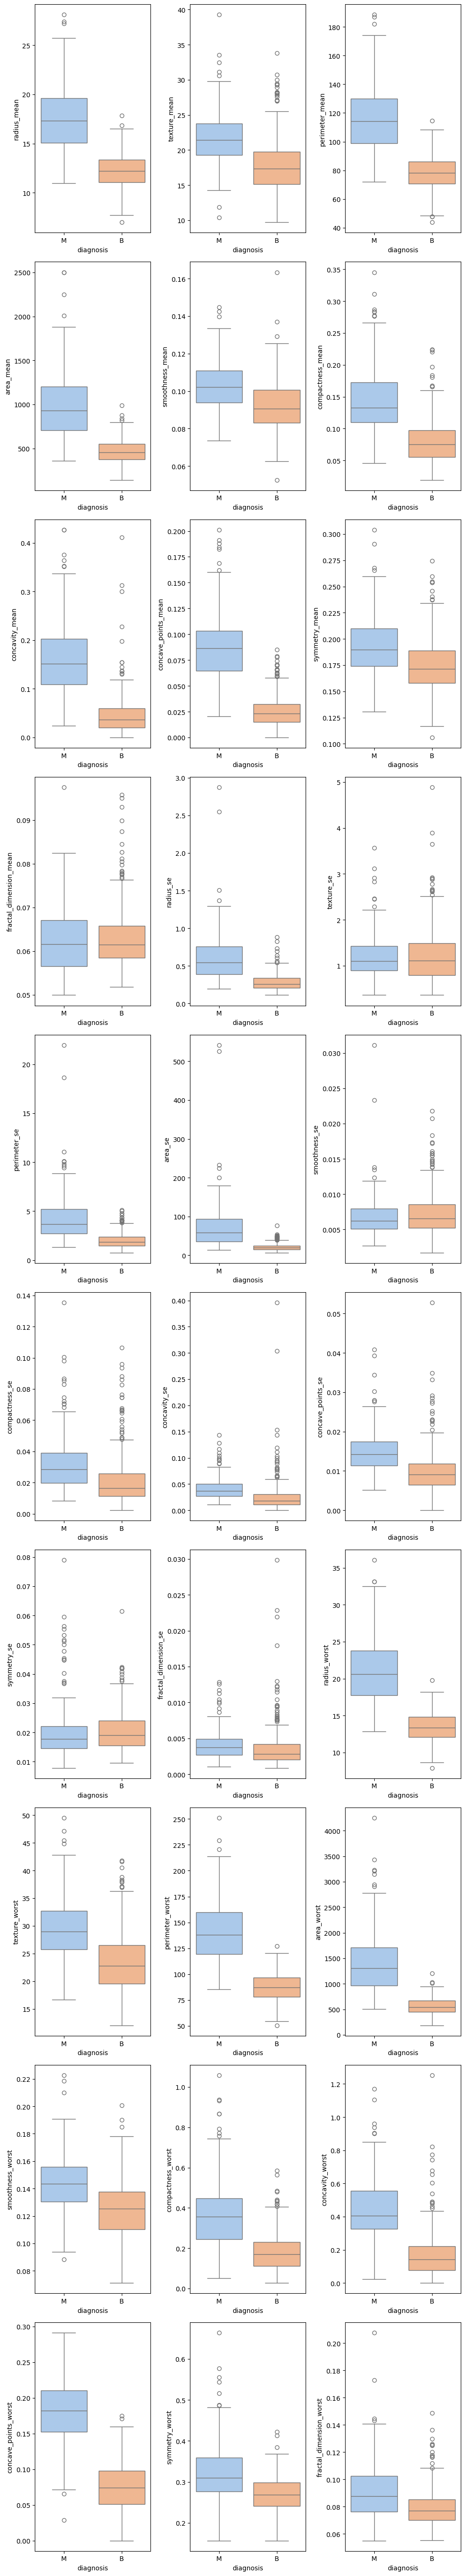

In [17]:
fig = plt.figure(figsize=(10,60))

for i in range(len(columns)):
  sub=fig.add_subplot(11,3, i+1)
  sns.boxplot(x='diagnosis', y=columns[i], data=df, palette='pastel', hue='diagnosis')
  plt.tight_layout()

Box plots show how numerical feature values differ across different target groups. In this case, they help confirm what the histograms above showed, that the size (perimeter, area, radius) and concave/concavity features are strong predictors of the output variable. The other features have some or significant overlap between the output variable ad are thus not strng predictors.

### 4. Split data into Training and Test Set

In [25]:
# Values in 'diagnosis' column need transforming to 1/0 for model training
label_encoder = preprocessing.LabelEncoder()
df["diagnosis"] = label_encoder.fit_transform(df["diagnosis"])

# Create training and test sets
X = df.drop(['diagnosis'], axis=1)
y = df["diagnosis"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training data shape: X={X_train.shape}, Y={y_train.shape}")
print(f"Test data shape: X={X_test.shape}, Y={y_test.shape}")

Training data shape: X=(455, 30), Y=(455,)
Test data shape: X=(114, 30), Y=(114,)


### 5. Build, Train and Evaluate a Model

#### Standardising features

In [28]:
# Initiate a logistic regression model
logistic_model = LogisticRegression(solver='liblinear')

logistic_model.fit(X_train, y_train) # Training the model
y_pred = logistic_model.predict(X_test) # Making predictions on the test set

# Evaluation metrics
accuracy_lm = round(metrics.accuracy_score(y_test, y_pred),2)
precision_lm = round(metrics.precision_score(y_test, y_pred),2)
recall_lm = round(metrics.recall_score(y_test, y_pred),2)
F1_lm = round(metrics.f1_score(y_test, y_pred),2)

# Print the metrics of the logistic regression classifier
print(f"Accuracy: {accuracy_lm}")
print(f"Precision: {precision_lm}")
print(f"Recall: {recall_lm}")
print(f"F1 Score: {F1_lm}")


Accuracy: 0.96
Precision: 0.97
Recall: 0.91
F1 Score: 0.94


This logistic regression model performed well with a high accuracy score (0.96) and high precision (0.97). These two metrics indicate that the model correctly classifies 96% of tumours and when it predicts malignant it is also quite accurate 97%. However, its recall score is lower (0.91) meaning it only identified 91% of the malignant tumours. This is a big problem as it leads to missed cancer diagnoses.

This baseline model can be imroved by standardising features so that ones with large values do not dominate smaller ones. Features which do not add significant difference to the predictions can be reomved. The hyperparameters can also be fine tuned. We can also use a stratified split so the test and training data keep the same proportions of each diagnosis.

### 6. Feature selection and Hyperparameter tuning

In [32]:
# Define a function to print the same metrics used by the baseline model
def print_metrics(model):
    y_pred = model.predict(X_test)
    print(f"Accuracy: {round(metrics.accuracy_score(y_test, y_pred), 2)}")
    print(f"Precision: {round(metrics.precision_score(y_test, y_pred), 2)}")
    print(f"Recall: {round(metrics.recall_score(y_test, y_pred), 2)}")
    print(f"F1 Score: {round(metrics.f1_score(y_test, y_pred), 2)}")

# Pipeline which scales the data first and then trains the model
scaled_model = Pipeline([('scaler', StandardScaler()),
                         ('model', LogisticRegression(solver='liblinear'))])

scaled_model.fit(X_train, y_train)
print_metrics(scaled_model)




Accuracy: 0.97
Precision: 0.98
Recall: 0.95
F1 Score: 0.96


There is a slight improvement in the accuracy and precision, but, a significant improvement in the recall (number of cancer diagnoses captured) and therefore in the F1 score. These improvements are due to the scaling which levels the outsize influence of larger scale values. Features with small values now contribute to the improved diagnosis (recall).

#### Feature selection

In [33]:
# Define model and parameters
model = Pipeline([('scaler', StandardScaler()),
                  ('select', SelectKBest(score_func=f_classif)),   # keeps the k best features
                  ('model', LogisticRegression(solver='liblinear'))])
k = [5, 10, 15, 20, 25, 30]

# Define grid search
parameter_grid = {'select__k': k}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=1001)
grid_search = GridSearchCV(estimator=model,
                           param_grid=parameter_grid,
                           n_jobs=-1,
                           cv=cv,
                           scoring='f1',
                           error_score=0)

fs_result = grid_search.fit(X_train, y_train) # STore result of feature selection

# Summarise results
print(f"Best: {grid_result.best_score_} using {grid_result.best_params_}")
means = fs_result.cv_results_['mean_test_score']
stds = fs_result.cv_results_['std_test_score']
params = fs_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
    print(f"{mean} ({stdev}) with: {param}")

# The features which were kept
selected = fs_result.best_estimator_.named_steps['select'].get_support()
print("Selected features:", list(X_train.columns[selected]))

# Evaluate the best model on the test set
print_metrics(fs_result.best_estimator_)

Best: 0.970804712554054 using {'model__C': 0.1, 'model__class_weight': None, 'model__penalty': 'l2', 'select__k': 30}
0.9191497696168268 (0.037701557679982914) with: {'select__k': 5}
0.9292134695547895 (0.029532179642110166) with: {'select__k': 10}
0.9317109507595255 (0.025310720136600382) with: {'select__k': 15}
0.9633211095928201 (0.02269588872511982) with: {'select__k': 20}
0.9601008668436237 (0.02147905039327726) with: {'select__k': 25}
0.9621739702871132 (0.01956874571118842) with: {'select__k': 30}
Selected features: ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'radius_se', 'perimeter_se', 'area_se', 'concave_points_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst']
Accuracy: 0.98
Precision: 1.0
Recall: 0.95
F1 Score: 0.98


The feature selection process dropped the number of features to 20 and kept the size and shape features as had been pridcted in the earlier exploratory data analysis. Other significant features have also been reatined. The model is now less complex and there is an improvement in the precision and F1 score but not in the recall.

#### Hyperparameter tuning

In [35]:
# Define the models and parameters
k = [fs_result.best_params_['select__k']]  # using the 20 features selected above
C = [0.01, 0.1, 1, 10, 100]                # strength of the regularisation
penalty = ['l1', 'l2']                     # type of the regularisation
class_weight = [None, 'balanced']          # 'balanced' gives more weight to the malignant class

# Define grid search
parameter_grid = {'select__k': k,
                  'model__C': C,
                  'model__penalty': penalty,
                  'model__class_weight': class_weight}

grid_search = GridSearchCV(estimator=model,
                           param_grid=parameter_grid,
                           n_jobs=-1,
                           cv=cv,
                           scoring='f1',
                           error_score=0)

tuned_result = grid_search.fit(X_train, y_train)

# Summarise results
print(f"Best: {tuned_result.best_score_} using {tuned_result.best_params_}")
means = tuned_result.cv_results_['mean_test_score']
stds = tuned_result.cv_results_['std_test_score']
params = tuned_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
    print(f"{mean} ({stdev}) with: {param}")


# Evaluate the best model on the test set
print_metrics(tuned_result.best_estimator_)

Best: 0.9678572174094561 using {'model__C': 0.1, 'model__class_weight': None, 'model__penalty': 'l2', 'select__k': 20}
0.8901938539700612 (0.03582253729312978) with: {'model__C': 0.01, 'model__class_weight': None, 'model__penalty': 'l1', 'select__k': 20}
0.9441255019572072 (0.03385978680385139) with: {'model__C': 0.01, 'model__class_weight': None, 'model__penalty': 'l2', 'select__k': 20}
0.888307716151821 (0.03481159515459202) with: {'model__C': 0.01, 'model__class_weight': 'balanced', 'model__penalty': 'l1', 'select__k': 20}
0.9474036438885225 (0.03192669135535173) with: {'model__C': 0.01, 'model__class_weight': 'balanced', 'model__penalty': 'l2', 'select__k': 20}
0.9575288191758589 (0.01764784004750957) with: {'model__C': 0.1, 'model__class_weight': None, 'model__penalty': 'l1', 'select__k': 20}
0.9678572174094561 (0.02113665226826424) with: {'model__C': 0.1, 'model__class_weight': None, 'model__penalty': 'l2', 'select__k': 20}
0.948251019807348 (0.02132064891023783) with: {'model__C

The scores have not changed from the reults of the feature selection. This could mean that the model was performing at its best limits after the standard scaling and feature selection. The hyperparameter tuning was therefore not able to make any further improvements to the model.

### Using an optimised Random Forest classifier as an alternative model



In [37]:
# Define models and parameters
model = RandomForestClassifier(random_state=42)
n_estimators = [10, 100, 1000]
max_features = ['sqrt', 'log2', len(X_train.columns)]

# Define grid search
parameter_grid = {'n_estimators': n_estimators,
                  'max_features': max_features}

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=1001)
grid_search = GridSearchCV(estimator=model,
                           param_grid=parameter_grid,
                           n_jobs=-1,
                           cv=cv,
                           scoring='f1',
                           error_score=0)

rf_result = grid_search.fit(X_train, y_train)   # training set only, so the test set stays unseen

# summarize results
print(f"Best: {rf_result.best_score_} using {rf_result.best_params_}")
means = rf_result.cv_results_['mean_test_score']
stds = rf_result.cv_results_['std_test_score']
params = rf_result.cv_results_['params']
for mean, stdev, param in zip(means, stds, params):
    print(f"{mean} ({stdev}) with: {param}")

# evaluate the best model on the test set
print_metrics(rf_result.best_estimator_)

Best: 0.9487124280439355 using {'max_features': 'log2', 'n_estimators': 1000}
0.9265438071410009 (0.03876396258292028) with: {'max_features': 'sqrt', 'n_estimators': 10}
0.9459856461365497 (0.027149296700803516) with: {'max_features': 'sqrt', 'n_estimators': 100}
0.9468939687254763 (0.02436523565495074) with: {'max_features': 'sqrt', 'n_estimators': 1000}
0.9378259812083342 (0.022997613305241887) with: {'max_features': 'log2', 'n_estimators': 10}
0.9419030125776915 (0.02630093573751161) with: {'max_features': 'log2', 'n_estimators': 100}
0.9487124280439355 (0.02287410926306501) with: {'max_features': 'log2', 'n_estimators': 1000}
0.9241732052887147 (0.036433077521011034) with: {'max_features': 30, 'n_estimators': 10}
0.9313670377158086 (0.023495052359853365) with: {'max_features': 30, 'n_estimators': 100}
0.9333455975354019 (0.026732971163766727) with: {'max_features': 30, 'n_estimators': 1000}
Accuracy: 0.96
Precision: 0.98
Recall: 0.93
F1 Score: 0.95


This optimised Random Forest performed slightly better than the baseline but did not outperform the tuned logistic regression. This suggests that a simpler, optimised linear model is the better choice for this dataset.